# 09 - TabKAN: ChebyshevKAN no churn de telecom

Quanto muda o KS de validação ao usar polinômios de Chebyshev nas conexões? A comparação emparelha cada fold com a KAN de três intervalos da E0. O fold 1 orienta a escolha e os outros dois descrevem a consistência do resultado.

Esta implementação local em PyTorch usa a variante polinomial do [TabKAN](https://github.com/aseslamian/TabKAN) com o treinamento compartilhado do projeto.

In [1]:
# Localiza o projeto a partir da raiz ou da pasta de notebooks.
from pathlib import Path
import sys

raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/config.py").exists())
sys.path.insert(0, str(raiz))
import pandas as pd
import torch
from src import config as cfg
from src.kan import ajustar, criar_spline
from src.tabkan import criar_chebyshev
from src.preprocess import load_preprocessed
from src.metrics import evaluate_sets, save_results

torch.set_num_threads(1)

## E0 - Base de Chebyshev de grau 3

Cada conexão recebe uma entrada escalar comprimida por tanh e aprende uma soma ponderada dos termos de graus 0 a 3. Isso permite curvatura suave ao longo da entrada. A transformação da entrada e a quantidade de coeficientes também diferem entre as arquiteturas.

Mantemos a variante neural, a largura 10, o Adam, a semente 42 e a regra de parada da KAN. A perda de validação seleciona a época. O KS mede a separação entre os escores das duas classes. O teste fica reservado à avaliação final.

In [2]:
# Treina apenas com as partições destinadas ao desenvolvimento.
config = dict(largura=10, grau=3, lr=0.001, lote=64, max_epocas=120,
              paciencia=15, min_delta=0.0001)
linhas = []
for fold in range(1, cfg.K_FOLDS + 1):
    dados = {c: load_preprocessed(fold, c, "neural") for c in ("treino", "validacao")}
    entradas = dados["treino"][0].shape[1]
    cheb = criar_chebyshev(entradas, config)
    spline = criar_spline(entradas, dict(largura=10, intervalos=3))
    n_cheb = sum(p.numel() for p in cheb.parameters())
    n_spline = sum(p.numel() for p in spline.parameters())
    scores, historia, epoca, segundos = ajustar(dados, config, cfg.SEED, criar_chebyshev)
    parametros = dict(config, parametros_treinaveis=n_cheb, melhor_epoca=epoca, epocas_rodadas=len(historia))
    linhas.append(evaluate_sets("tabkan", "neural", fold, scores, hiperparametros=parametros,
                                etapa="E0_baseline", semente=cfg.SEED))
    print(f"Fold {fold}: {n_cheb} parâmetros (KAN: {n_spline}), época {epoca}/{len(historia)}, {segundos:.1f} s")
resultado = pd.concat(linhas, ignore_index=True)
save_results(resultado)

Fold 1: 1640 parâmetros (KAN: 1241), época 7/22, 2.2 s
Fold 2: 1640 parâmetros (KAN: 1241), época 5/20, 0.5 s
Fold 3: 1640 parâmetros (KAN: 1241), época 11/26, 0.7 s


In [3]:
# Calcula a diferença de KS para a mesma etapa, semente, variante e fold.
kan = pd.read_csv(cfg.REPORTS_TABLES / "resultados_kan.csv")
comparacao = pd.concat([kan, resultado]).query(
    "etapa == 'E0_baseline' and semente == @cfg.SEED and variante == 'neural' and conjunto == 'validacao'"
).pivot(index="fold", columns="modelo", values="ks")
comparacao["delta"] = comparacao["tabkan"] - comparacao["kan"]
comparacao.loc["Média"] = comparacao.mean()
print(comparacao.round(4).to_string())

modelo     kan  tabkan   delta
fold                          
1       0.5043  0.5078  0.0035
2       0.5157  0.5302  0.0145
3       0.5386  0.5386 -0.0000
Média   0.5195  0.5255  0.0060


## Registro do processo

O KS médio da ChebyshevKAN foi 0.5255, frente a 0.5195 da KAN. No fold 1, a diferença foi +0.0035. A ChebyshevKAN superou a referência em 2 dos três folds. Esta rodada cobre uma única semente. Uma próxima rodada pode reduzir o grau para 2 e verificar se o termo cúbico contribui para o KS.

## Estabilidade da comparação entre sementes

O ganho observado com a semente 42 se repete quando variam a inicialização e a ordem dos lotes? Mantemos os folds e as configurações E0. Reaproveitamos a semente 42 e acrescentamos 43 e 44, como na MLP. Cada diferença compara os modelos no mesmo fold e na mesma semente. As repetições compartilham dados, portanto descrevem a estabilidade do treinamento.

In [4]:
# Repete as configurações E0 com as duas sementes adicionais.
config_spline = {k: v for k, v in config.items() if k != "grau"}
config_spline["intervalos"] = 3
for nome, fabrica, parametros_base in [("kan", criar_spline, config_spline),
                                       ("tabkan", criar_chebyshev, config)]:
    registros = []
    for fold in range(1, cfg.K_FOLDS + 1):
        dados = {c: load_preprocessed(fold, c, "neural") for c in ("treino", "validacao")}
        rede = fabrica(dados["treino"][0].shape[1], parametros_base)
        quantidade = sum(p.numel() for p in rede.parameters())
        for semente in (43, 44):
            scores, historia, epoca, _ = ajustar(dados, parametros_base, semente, fabrica)
            parametros = dict(parametros_base, melhor_epoca=epoca, epocas_rodadas=len(historia),
                              parametros_treinaveis=quantidade)
            registros.append(evaluate_sets(nome, "neural", fold, scores, hiperparametros=parametros,
                                           etapa="E0_baseline", semente=semente))
    save_results(pd.concat(registros, ignore_index=True))

In [5]:
# Confere os nove pares antes de calcular as médias por fold.
tabelas = [pd.read_csv(cfg.REPORTS_TABLES / f"resultados_{m}.csv") for m in ("kan", "tabkan")]
validacao = pd.concat(tabelas).query(
    "etapa == 'E0_baseline' and variante == 'neural' and conjunto == 'validacao' and semente in [42, 43, 44]"
)
pares = validacao.pivot(index=["fold", "semente"], columns="modelo", values="ks").sort_index()
esperado = pd.MultiIndex.from_product([range(1, 4), [42, 43, 44]], names=pares.index.names)
assert pares.index.equals(esperado) and pares.notna().all().all()
pares["delta"] = pares["tabkan"] - pares["kan"]
resumo = pares.groupby(level="fold").mean()
print(pares.round(5).to_string())
print(resumo.round(5).to_string())
print(resumo.mean().round(5).to_string())

modelo            kan   tabkan    delta
fold semente                           
1    42       0.50435  0.50783  0.00348
     43       0.50203  0.52000  0.01797
     44       0.49971  0.51130  0.01159
2    42       0.51566  0.53016  0.01450
     43       0.51624  0.53480  0.01856
     44       0.51566  0.53538  0.01972
3    42       0.53855  0.53855 -0.00000
     43       0.53971  0.52174 -0.01797
     44       0.53275  0.53797  0.00522
modelo      kan   tabkan    delta
fold                             
1       0.50203  0.51304  0.01101
2       0.51585  0.53345  0.01759
3       0.53700  0.53275 -0.00425
modelo
kan       0.51830
tabkan    0.52642
delta     0.00812


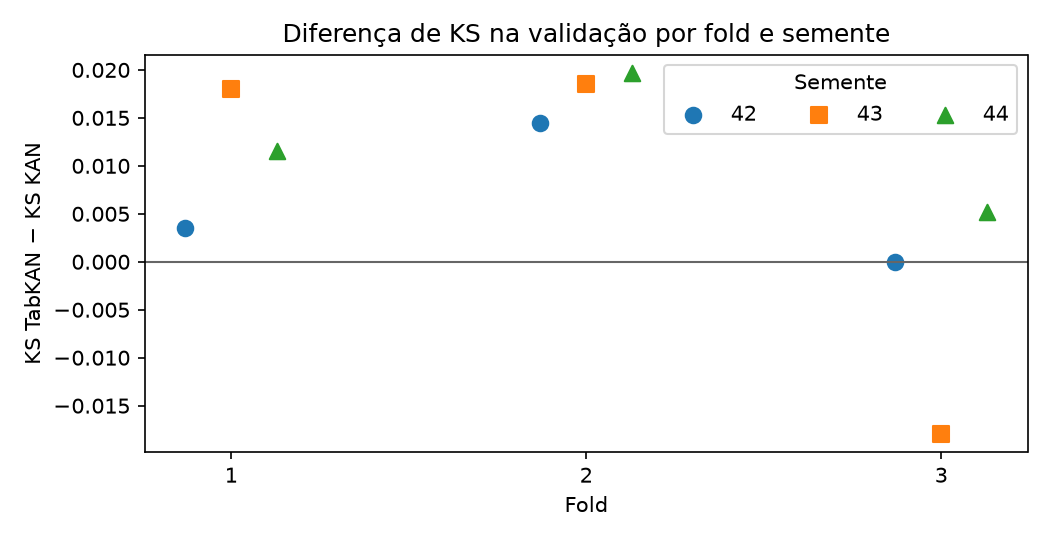

In [6]:
# A linha zero separa os ganhos da ChebyshevKAN dos ganhos da KAN.
import matplotlib.pyplot as plt

fig, eixo = plt.subplots(figsize=(7, 3.6))
for semente, deslocamento, marcador in [(42, -0.13, "o"), (43, 0, "s"), (44, 0.13, "^")]:
    serie = pares.xs(semente, level="semente")["delta"]
    eixo.scatter(serie.index + deslocamento, serie, marker=marcador, s=55, label=str(semente))
eixo.axhline(0, color="0.4", linewidth=1)
eixo.set(xticks=[1, 2, 3], xlabel="Fold", ylabel="KS TabKAN − KS KAN",
         title="Diferença de KS na validação por fold e semente")
eixo.legend(title="Semente", ncol=3)
fig.tight_layout()
arquivo = cfg.REPORTS_FIGURES / "09_tabkan_delta_ks_sementes.png"
fig.savefig(arquivo, dpi=150)
plt.show()

### Resultado das repetições

Nas sementes 42, 43 e 44, o KS médio foi 0.5183 para a KAN e 0.5264 para a ChebyshevKAN (diferença +0.0081). A ChebyshevKAN obteve KS maior em 7 pares, menor em 1 e empatou em 1, considerando a precisão numérica. O gráfico permite verificar se a direção da diferença se mantém dentro de cada fold. A conclusão se restringe a estas configurações e partições.